# SOSora: evidence notebook
Every number below is read from files saved in this repository during the hackathon (no typed-in results).
**SOSora** keeps the rescue map alive when the towers and the roads go down: one GPU box in a command truck runs **NVIDIA Nemotron 3.5 Lightning** on **vLLM** as a tool-calling agent over real OpenStreetMap roads, graded with **NVIDIA NeMo Gym**.
All scenarios are simulated.

In [1]:
import json, pathlib, collections
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
plt.rcParams.update({'figure.facecolor':'#090b0e','axes.facecolor':'#0e1b25','axes.edgecolor':'#29404c','text.color':'#f4f7f8',
                     'axes.labelcolor':'#b4c7d0','xtick.color':'#b4c7d0','ytick.color':'#b4c7d0','font.size':11})
def load(p): return json.loads((ROOT/p).read_text())
print('repo:', ROOT.name)

repo: sosora


## 1. Parameter budget (hackathon cap: 33B total, all experts counted)

In [2]:
t = load('docs/evidence/param_budget_2026-10-18/totals.json')
rows = [('Nemotron 3.5 Lightning (full checkpoint, all experts + MTP)', t['nemotron_full_checkpoint_parameters']),
        ('SegFormer-B0 vision (served once)', t['segformer_parameters'])]
import re
m = re.search(r'tiny\.en.*?\|\s*([\d,]+)\s*\|', (ROOT/'docs/PARAM_BUDGET.md').read_text())
if m: rows.append(('faster-whisper tiny.en ASR', int(m.group(1).replace(',', ''))))
total = sum(n for _, n in rows)
for name, n in rows: print(f'{name:<62} {n:>16,}')
print(f"{'TOTAL served':<62} {total:>16,}   cap {t['cap']:,}   under cap: {total <= t['cap']}")
print(f"Rejected alternative: Parakeet ASR ({t['parakeet_parameters']:,}) would exceed the cap.")

Nemotron 3.5 Lightning (full checkpoint, all experts + MTP)      32,913,263,168
SegFormer-B0 vision (served once)                                     3,714,658
faster-whisper tiny.en ASR                                           37,760,256
TOTAL served                                                     32,954,738,082   cap 33,000,000,000   under cap: True
Rejected alternative: Parakeet ASR (617,825,926) would exceed the cap.


## 2. Red Hat vLLM: serving surge (100 simulated radio reports)

concurrency   1: 100/100 ok, 84.8 s, 1.18 msg/s
concurrency 100: 100/100 ok, 20.6 s, 4.85 msg/s


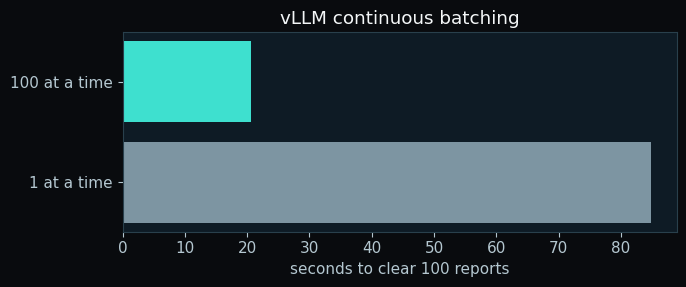

In [3]:
s = load('docs/evidence/vllm_2026-10-17/surge.json')
b = s['batches']
for x in b: print(f"concurrency {x['concurrency']:>3}: {x['successes']}/{x['requests']} ok, {x['elapsed_seconds']:.1f} s, {x['successful_messages_per_second']:.2f} msg/s")
fig, ax = plt.subplots(figsize=(7,3))
ax.barh([f"{x['concurrency']} at a time" for x in b], [x['elapsed_seconds'] for x in b], color=['#7d95a2','#3ee0cf'])
ax.set_xlabel('seconds to clear 100 reports'); ax.set_title('vLLM continuous batching'); plt.tight_layout(); plt.show()

## 3. Live reliability on vLLM (30 runs, fresh seed each)

In [4]:
r = load('docs/evidence/reliability_2026-10-18/summary.json')
for k in ['correct_beacon_segment','exact_five_cut_off','guarded_final_ambiguity','strict_ambiguity_no_mutation_attempt']:
    print(f"{k:<40} {r[k]['numerator']}/{r[k]['denominator']}")
print('unsafe ambiguous mutations rejected by code:', len(r['ambiguous_mutation_attempt_runs_rejected_by_code']))
print('note:', r['important_limit'][:220])

correct_beacon_segment                   20/20
exact_five_cut_off                       20/20
guarded_final_ambiguity                  10/10
strict_ambiguity_no_mutation_attempt     1/10
unsafe ambiguous mutations rejected by code: 9
note: Final guarded state correctness is not model-only ambiguity compliance. Nine ambiguous runs attempted to report both bridges; deterministic code rejected them. Some summaries loosely describe rejected reports as recorded


## 4. NVIDIA NeMo Gym: sealed fresh exam 2 (42 unseen scenarios × 3 runs per arm)

Baseline              39/126  = 31%
+ system prompt       90/126  = 71%
+ argument repair    123/126  = 98%


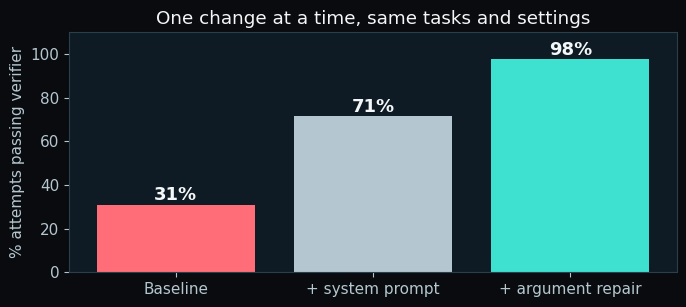

In [5]:
EV = ROOT/'ml/nemo_gym/evidence/test_fresh2_relaunch_2026-10-18'
fam = {json.loads(l)['scenario_id']: json.loads(l)['scenario']['family'] for l in (ROOT/'ml/nemo_gym/data/test_fresh2.jsonl').read_text().splitlines()}
arms = [('baseline','Baseline'),('grounded_v2','+ system prompt'),('grounded_v2_nullable','+ argument repair')]
res = {}
for a,_ in arms:
    res[a] = []
    for k in (1,2,3):
        for l in (EV/f'{a}_r{k}'/'raw/rollouts.jsonl').read_text().splitlines():
            x = json.loads(l); res[a].append((fam[x['scenario_id']], x['reward'] >= 1))
rates = {a: sum(p for _,p in res[a])/len(res[a]) for a,_ in arms}
for a,l in arms: print(f'{l:<20} {sum(p for _,p in res[a]):>3}/{len(res[a])}  = {rates[a]:.0%}')
fig, ax = plt.subplots(figsize=(7,3.2))
ax.bar([l for _,l in arms], [100*rates[a] for a,_ in arms], color=['#ff6d78','#b4c7d0','#3ee0cf'])
for i,(a,_) in enumerate(arms): ax.text(i, 100*rates[a]+2, f'{rates[a]:.0%}', ha='center', fontsize=13, fontweight='bold')
ax.set_ylim(0,110); ax.set_ylabel('% attempts passing verifier'); ax.set_title('One change at a time, same tasks and settings'); plt.tight_layout(); plt.show()

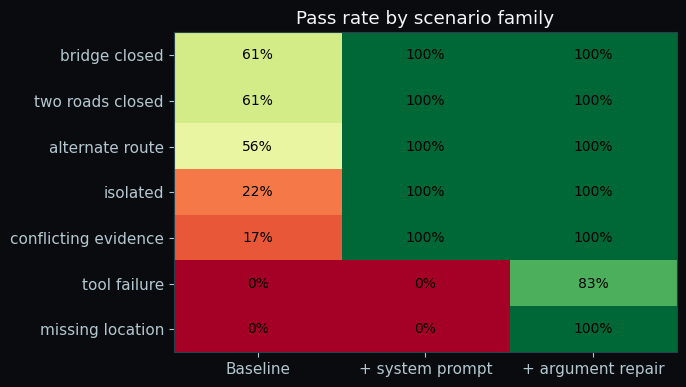

In [6]:
fams = ['bridge_closed','two_roads_closed','alternate_route','isolated','conflicting_evidence','tool_failure','missing_location']
grid = [[sum(p for f,p in res[a] if f==fm)/max(1,sum(1 for f,_ in res[a] if f==fm)) for a,_ in arms] for fm in fams]
fig, ax = plt.subplots(figsize=(7,4))
im = ax.imshow(grid, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(3)); ax.set_xticklabels([l for _,l in arms]); ax.set_yticks(range(len(fams))); ax.set_yticklabels([f.replace('_',' ') for f in fams])
for i,row in enumerate(grid):
    for j,v in enumerate(row): ax.text(j, i, f'{v:.0%}', ha='center', va='center', color='black', fontsize=10)
ax.set_title('Pass rate by scenario family'); plt.tight_layout(); plt.show()

### What the argument repair actually changed (audited)

In [7]:
rep = json.loads((EV/'adapter_repairs.json').read_text())
print('field edits:', rep['field_edits'], '| by family:', rep['by_family'], '| original spelling:', rep['by_original_spelling'])
e = rep['edits'][0]; print('example:', e['tool'], e['field'], repr(e['before']), '->', e['after'])

field edits: 36 | by family: {'tool_failure': 18, 'missing_location': 18} | original spelling: {'None': 36}
example: submit_recommendation graph_version 'None' -> None


### One real rollout: the same tool-failure scenario, baseline vs repaired

In [8]:
sid = e['scenario_id']
def show(run):
    for l in (EV/run/'raw/rollouts.jsonl').read_text().splitlines():
        x = json.loads(l)
        if x['scenario_id'] != sid: continue
        print(f"--- {run}  reward={x['reward']}  issues={x['issues']}")
        for t in x['trajectory']:
            if t['type']=='function_call': print('  CALL', t['name'], t['arguments'][:160])
            elif t['type']=='function_call_output': print('    ->', t['output'][:120])
show('baseline_r1'); show(e['run'])

--- baseline_r1  reward=0.0  issues=['invalid_tool_arguments', 'missing_required_tools', 'require_exactly_one_recommendation', 'route_tool_before_current_status', 'stale_graph_version']
  CALL get_incident {}
    -> {"report": "SOS: stranded residents request rescue. Reported location: node_18.", "rescue_node": "node_0", "incident_nod
  CALL get_road_status {}
    -> {"available": false, "error": "simulated_tool_failure", "graph_version": null}
  CALL get_damage_evidence {}
    -> {"evidence": [], "review_status": "unverified", "note": "Vision evidence does not override authoritative closures."}
  CALL check_reachability {"graph_version": 1}
    -> {"available": false, "error": "stale_graph_version", "graph_version": 2}
  CALL calculate_candidate_routes {"graph_version": 2}
    -> {"available": false, "error": "insufficient_current_status"}
  CALL get_road_status {}
    -> {"available": false, "error": "simulated_tool_failure", "graph_version": null}
  CALL submit_recommendation {"grap

## 5. Vision (hub layer): honest sealed result

In [9]:
v = load('docs/ml/evidence/v3_2026-10-18/final_evaluation.json')
def find(o, path=''):
    if isinstance(o, dict):
        for k, val in o.items(): yield from find(val, f'{path}.{k}')
    elif isinstance(o, (int, float)) and 'f1' in path.lower(): yield path, o
for p, val in list(find(v))[:8]: print(f'{p:<70} {val:.4f}')
print('V3 lost on the sealed 38 tiles and was not promoted; imagery is treated as a clue, never proof.')

.metrics.v2.f1                                                         0.3065
.metrics.v3.f1                                                         0.2736
.metrics.all_positive.f1                                               0.2612
.metrics.all_negative.f1                                               0.0000
V3 lost on the sealed 38 tiles and was not promoted; imagery is treated as a clue, never proof.


Reproduce scoring: see `docs/GYM_RESULTS.md` (Reproduce section). Visual click-through of every Gym attempt: `docs/gym/index.html`.